In [ ]:
##################################################################################################
##        This notebook is used to analyze and plot the In-situ Raman spectroscopy data         ##
##        for the nanostructuring of Cu electrodes with NaCl and KI.                            ##
##        It includes the following steps:                                                      ##
##          1. Read the raw electrochemical data from the mpt files                             ##
##          2. Read the pre-processed Raman data from the wdf files                             ##
##          3. Perform the peak deconvolution for the selected Raman signals                    ##
##          4. Plot the results                                                                 ##
##                                                                                              ##
## Notebook developed in 06/2026 and updated on 30/09/2026 by Camilo A. Mesa & Sebastián Murcia ##
##################################################################################################

In [2]:
# Here packages are imported and helper functions are defined in the next cell.
# Two particular packages are used in this notebook: ixdat and ramanspy for reading and analysing the electrochemical and Raman data, respectively.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from functools import partial
from ixdat.techniques.cv import CyclicVoltammogram
import ramanspy as rp
from renishawWiRE import WDFReader
from renishawWiRE.types import DataType
from scipy.optimize import curve_fit
import ipywidgets as widgets
from ipywidgets import interact
import plotly.graph_objects as go

importing ixdat v0.3.0 from C:\Users\cmesa\AppData\Roaming\Python\Python313\site-packages\ixdat\__init__.py


### Helper functions

- `get_wdf_frame_times`: reads the real per-spectrum acquisition time stored in a Renishaw `.wdf` file (falls back to a uniform time grid if not available).
- `load_and_correlate`: reads the CV file and the pre-processed Raman map, and interpolates potential/current onto the real Raman time base — flagging any Raman frames that fall outside the CV's recorded time range.
- `gaussian`, `double_gaussian`, `components`: the two-Gaussian + linear-baseline model used for the deconvolution.
- `initial_guess_double_gaussian`, `fit_double_gaussian_series`: build the initial guess and run the fit spectrum-by-spectrum over a chosen region.
- `deconvolution_results_to_df`: collect the fitted parameters (center, FWHM, area) into an organised DataFrame.
- `plot_fit_check`, `plot_time_alignment`: QC and summary figures.
- `spectrum_browser`: interactive slider to page through raw spectra before fitting.

In [3]:
def get_wdf_frame_times(wdf_path):
    """
    Return the real per-spectrum acquisition time (s) recorded in a Renishaw
    .wdf file's origin list (present for time-series "Series" measurements).
    Returns None if no Time origin entry is found.
    """
    reader = WDFReader(wdf_path)
    t = None
    for entry in reader.origin_list_header:
        _is_primary, data_type, _unit_type, _label, values = entry
        if data_type == DataType.Time:
            t = np.asarray(values, dtype=float)
            break
    reader.close()
    return t

def load_and_correlate(cv_path, raman_path, t_ram_total=None, n_spec=None, cv_reader="biologic"):
    """
    Load the electrochemistry (CV) file and the pre-processed in-situ Raman
    map, and interpolate the applied potential/current onto the Raman
    acquisition time base.

    Raman frame times are taken from the .wdf file's own per-spectrum
    timestamps whenever available (recommended, and used by default).

    Raman frames whose time falls outside the CV file's own recorded time
    range get NaN potential/current — check `extra_spectra` in the returned dict, and
    `plot_time_alignment` below.

    Returns
    -------
    dict with keys: cv, spectra, x, Y, t_raman, E_interp, i_interp, extra_spectra
    """
    cv = CyclicVoltammogram.read(cv_path, reader=cv_reader)
    spectra = rp.load.renishaw(raman_path)

    x = np.asarray(spectra.spectral_axis, dtype=float)
    Y = np.asarray(spectra.spectral_data, dtype=float)

    t_raman = get_wdf_frame_times(raman_path)
    if t_raman is None:
        if n_spec is None:
            n_spec = Y.shape[0]
        if t_ram_total is None:
            raise ValueError(
                "No per-frame timestamps found in the .wdf file; "
                "please supply t_ram_total for a uniform-grid fallback.")
        t_raman = np.arange(Y.shape[0]) * (t_ram_total / n_spec)

    t_ec, E = cv.grab("potential")
    _, I = cv.grab("current")

    in_range = (t_raman >= t_ec.min()) & (t_raman <= t_ec.max())
    extra_spectra = dict(
        n_frames=len(t_raman), n_in_range=int(in_range.sum()),
        cv_t_range=(float(t_ec.min()), float(t_ec.max())),
        raman_t_range=(float(t_raman.min()), float(t_raman.max())),)
    if not in_range.all():
        n_out = int((~in_range).sum())
        print(f"load_and_correlate: {n_out}/{len(t_raman)} Raman frames fall outside the CV "
              f"recorded time range (CV: {t_ec.min():.1f}-{t_ec.max():.1f} s, "
              f"Raman: {t_raman.min():.1f}-{t_raman.max():.1f} s). "
              "Their potential/current are set to NaN (see plot_time_alignment below).")

    E_interp = np.interp(t_raman, t_ec, E, left=np.nan, right=np.nan)
    i_interp = np.interp(t_raman, t_ec, I, left=np.nan, right=np.nan)

    return dict(cv=cv, spectra=spectra, x=x, Y=Y,
                t_raman=t_raman, E_interp=E_interp, i_interp=i_interp,
                extra_spectra=extra_spectra)

In [16]:
def gaussian(x, A, x0, sigma):
    return A * np.exp(-0.5 * ((x - x0) / sigma) ** 2)

def double_gaussian(x, A1, x01, s1, A2, x02, s2, c0, c1, xref):
    baseline = c0 + c1 * (x - xref)
    return gaussian(x, A1, x01, s1) + gaussian(x, A2, x02, s2) + baseline

def components(x, popt, xref):
    A1, x01, s1, A2, x02, s2, c0, c1 = popt
    p1 = gaussian(x, A1, x01, s1)
    p2 = gaussian(x, A2, x02, s2)
    baseline = c0 + c1 * (x - xref)
    total = p1 + p2 + baseline
    return p1, p2, baseline, total

def initial_guess_double_gaussian(x, y, xref, centers_guess, sigmas_guess, search_halfwidth=10.0):
    """
    Estimate initial parameters for the two-Gaussian + linear-baseline fit.

    A linear baseline is estimated from the edges of the fitting window;
    each peak's amplitude is then estimated as the max of the
    baseline-corrected signal within +/- `search_halfwidth` of its guessed
    center.
    """
    n_edge = 6
    xx = np.r_[x[:n_edge], x[-n_edge:]]
    yy = np.r_[y[:n_edge], y[-n_edge:]]
    slope, intercept = np.polyfit(xx, yy, 1)

    c1 = slope
    c0 = intercept + slope * xref
    baseline = c0 + c1 * (x - xref)
    y_corr = y - baseline

    amps = []
    for c in centers_guess:
        window = (x >= c - search_halfwidth) & (x <= c + search_halfwidth)
        amps.append(max(1.0, np.nanmax(y_corr[window])) if window.any() else 1.0)

    return np.array([
        amps[0], centers_guess[0], sigmas_guess[0],
        amps[1], centers_guess[1], sigmas_guess[1],
        c0, c1,], dtype=float)

def fit_double_gaussian_series(x, Y, region, centers_guess, sigmas_guess,
                                lower_bounds, upper_bounds,
                                search_halfwidth=10.0, maxfev=50000):
    """
    Fit the two-Gaussian + linear-baseline model to every spectrum (row of
    `Y`) within `region`. The amplitude and baseline of a successful fit are
    carried over as the initial guess for the next spectrum, which helps
    convergence across a time series.

    `centers_guess`, `sigmas_guess`, `lower_bounds`, `upper_bounds` follow
    the parameter order (A1, x01, s1, A2, x02, s2, c0, c1); centers/sigmas
    guesses are given as (peak1, peak2).

    Returns a dict with: x_fit, xref, Y_fit, fit_params, fit_curves,
    fit_components, r2_values.
    """
    mask = (x >= region[0]) & (x <= region[1])
    x_fit = x[mask]
    Y_fit = Y[:, mask]
    xref = x_fit.mean()

    model = partial(double_gaussian, xref=xref)
    lower_bounds = np.asarray(lower_bounds, dtype=float)
    upper_bounds = np.asarray(upper_bounds, dtype=float)

    fit_params, fit_curves, fit_components_list, r2_values = [], [], [], []
    last_good = None

    for y in Y_fit:
        p0 = initial_guess_double_gaussian(x_fit, y, xref, centers_guess, sigmas_guess, search_halfwidth)
        if last_good is not None:
            p0[[0, 3, 6, 7]] = last_good[[0, 3, 6, 7]]
        p0 = np.minimum(np.maximum(p0, lower_bounds + 1e-9), upper_bounds - 1e-9)

        try:
            popt, _ = curve_fit(model, x_fit, y, p0=p0,
                                 bounds=(lower_bounds, upper_bounds), maxfev=maxfev)
            p1, p2, baseline, total = components(x_fit, popt, xref)
            ss_res = np.sum((y - total) ** 2)
            ss_tot = np.sum((y - np.mean(y)) ** 2)
            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
            last_good = popt
        except (RuntimeError, ValueError):
            popt = np.full(8, np.nan)
            p1 = p2 = baseline = total = np.full_like(x_fit, np.nan)
            r2 = np.nan
            last_good = None

        fit_params.append(popt)
        fit_curves.append(total)
        fit_components_list.append(np.vstack([p1, p2, baseline]))
        r2_values.append(r2)

    return dict(
        x_fit=x_fit, xref=xref, Y_fit=Y_fit,
        fit_params=np.vstack(fit_params),
        fit_curves=np.vstack(fit_curves),
        fit_components=np.stack(fit_components_list),
        r2_values=np.asarray(r2_values),)

def deconvolution_results_to_df(fit, t_raman, E_interp, i_interp,
                                 peak1_label="peak1", peak2_label="peak2"):
    """Collect fitted parameters into a tidy DataFrame (center, FWHM, area per peak)."""
    A1, x01, s1, A2, x02, s2, c0, c1 = fit["fit_params"].T
    fwhm_factor = 2 * np.sqrt(2 * np.log(2))
    fwhm1, fwhm2 = fwhm_factor * s1, fwhm_factor * s2
    area1 = A1 * s1 * np.sqrt(2 * np.pi)
    area2 = A2 * s2 * np.sqrt(2 * np.pi)

    return pd.DataFrame({
        "time_s": t_raman, "potential_V": E_interp, "current_A": i_interp,
        f"{peak1_label}_center_cm-1": x01, f"{peak1_label}_height": A1,
        f"{peak1_label}_sigma_cm-1": s1, f"{peak1_label}_FWHM_cm-1": fwhm1, f"{peak1_label}_area": area1,
        f"{peak2_label}_center_cm-1": x02, f"{peak2_label}_height": A2,
        f"{peak2_label}_sigma_cm-1": s2, f"{peak2_label}_FWHM_cm-1": fwhm2, f"{peak2_label}_area": area2,
        "baseline_c0": c0, "baseline_c1": c1,
        "R2": fit["r2_values"],})

In [4]:
def plot_fit_check(fit, index, peak1_label="Peak 1", peak2_label="Peak 2"):
    """Plot data, total fit, individual components and residual for one spectrum."""
    x_fit, xref = fit["x_fit"], fit["xref"]
    y = fit["Y_fit"][index]
    popt = fit["fit_params"][index]
    p1, p2, baseline, total = components(x_fit, popt, xref)

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(x_fit, y, label="Data")
    ax.plot(x_fit, total, label="Total fit")
    ax.plot(x_fit, p1, "--", label=peak1_label)
    ax.plot(x_fit, p2, "--", label=peak2_label)
    ax.plot(x_fit, y - total, label="Residual")

    ax.set_xlabel("Raman shift / cm$^{-1}$")
    ax.set_ylabel("Intensity")
    ax.set_title(f"Fit check — spectrum {index} (R$^2$ = {fit['r2_values'][index]:.3f})")
    ax.legend()
    plt.tight_layout()
    plt.show()

def plot_time_alignment(cv, t_raman, E_interp):
    """
    Overlay the raw CV potential trace and the interpolated Raman-frame
    potentials, to visually check the time alignment/coverage between the
    two data sets (and spot any NaN frames outside the CV's time range).
    """
    t_ec, E = cv.grab("potential")

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(t_ec, E, lw=1, alpha=0.5, label="CV (raw)")
    ax.plot(t_raman, E_interp, "o", ms=3, color="crimson", label="Raman frames (interpolated)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("E vs Ag/AgCl (V)")
    ax.set_title("Time alignment check: CV vs Raman frames")
    ax.legend()
    plt.tight_layout()
    plt.show()

def spectrum_browser(x, Y, xmin=100, xmax=1200):
    mask = (x >= xmin) & (x <= xmax)
    xm = x[mask]

    def _plot(idx=0):
        fig = go.Figure(go.Scatter(x=xm, y=Y[idx][mask], mode="lines"))
        fig.update_layout(
            title=f"Spectrum {idx}",
            xaxis_title="Raman shift / cm⁻¹",
            yaxis_title="Intensity / a.u.",
            width=800, height=450,
        )
        fig.show()

    interact(_plot, idx=widgets.IntSlider(min=0, max=Y.shape[0] - 1, step=1, value=0, description="Spectrum"))

### Read the raw electrochemical data and the pre-processed Raman data for the nanostructuring experiments

`load_and_correlate` reads the real per-spectrum timestamps stored in the `.wdf` file.

In [13]:
# Upon loading and correlating, the nanostructuring data comparing the 2 electrolyte compositions, 
# the loaded data has the following naming structure:
# m_aa_nanostructuging_bb, where m stands for measurement number from the original dataset, aa is the measurement number and bb the electrolyte

m22_nanostructuring_NaCl = load_and_correlate(
    cv_path="22_1M NaCl - Cu4_polished_CuCE_2V_100mV_1s_15cycles_C01.mpt",
    raman_path="22_Nanostructuring_NaCl_WiRE_treated.wdf",)

x_m22_nanostructuring_NaCl, Y_m22_nanostructuring_NaCl = m22_nanostructuring_NaCl["x"], m22_nanostructuring_NaCl["Y"]
t_raman_m22_nanostructuring_NaCl, E_interp_m22_nanostructuring_NaCl, i_interp_m22_nanostructuring_NaCl = m22_nanostructuring_NaCl["t_raman"], m22_nanostructuring_NaCl["E_interp"], m22_nanostructuring_NaCl["i_interp"]
m22_nanostructuring_NaCl["extra_spectra"]

load_and_correlate: 35/600 Raman frames fall outside the CV recorded time range (CV: 0.0-1182.0 s, Raman: 0.0-1254.8 s). Their potential/current are set to NaN (see plot_time_alignment below).


C:\Users\cmesa\AppData\Local\Temp\ipykernel_31692\1425987870.py:35: ResourceWarning: unclosed file <_io.BufferedReader name='22_Nanostructuring_NaCl_WiRE_treated.wdf'>
  spectra = rp.load.renishaw(raman_path)


{'n_frames': 600,
 'n_in_range': 565,
 'cv_t_range': (0.0, 1182.0417702198029),
 'raman_t_range': (0.0, 1254.770248413086)}

In [14]:
m27_nanostructuring_KI = load_and_correlate(
    cv_path="27_1M KI - Cu5_polished_CuCE_2V_100mV_1s_15cycles_C01.mpt",
    raman_path="27_Nanostructuring_KI_WiRE_treated.wdf",)

x_m27_nanostructuring_KI, Y_m27_nanostructuring_KI = m27_nanostructuring_KI["x"], m27_nanostructuring_KI["Y"]
t_raman_m27_nanostructuring_KI, E_interp_m27_nanostructuring_KI, i_interp_m27_nanostructuring_KI = m27_nanostructuring_KI["t_raman"], m27_nanostructuring_KI["E_interp"], m27_nanostructuring_KI["i_interp"]
m27_nanostructuring_KI["extra_spectra"]

load_and_correlate: 34/600 Raman frames fall outside the CV recorded time range (CV: 0.0-1183.9 s, Raman: 0.0-1254.8 s). Their potential/current are set to NaN (see plot_time_alignment below).


C:\Users\cmesa\AppData\Local\Temp\ipykernel_31692\1425987870.py:35: ResourceWarning: unclosed file <_io.BufferedReader name='27_Nanostructuring_KI_WiRE_treated.wdf'>
  spectra = rp.load.renishaw(raman_path)


{'n_frames': 600,
 'n_in_range': 566,
 'cv_t_range': (0.0, 1183.941169977188),
 'raman_t_range': (0.0, 1254.7550659179688)}

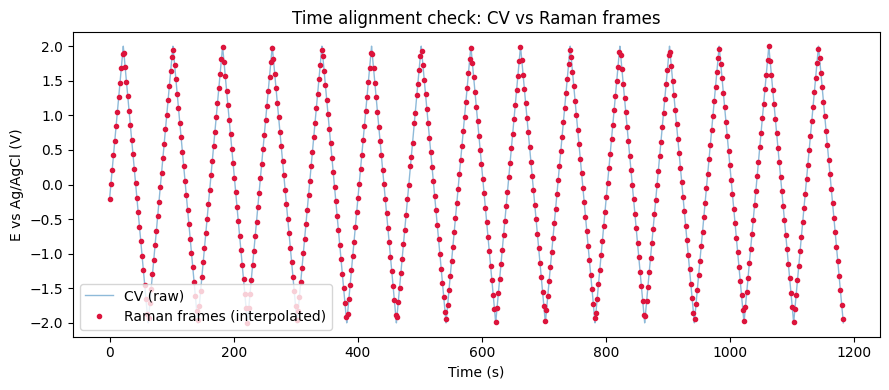

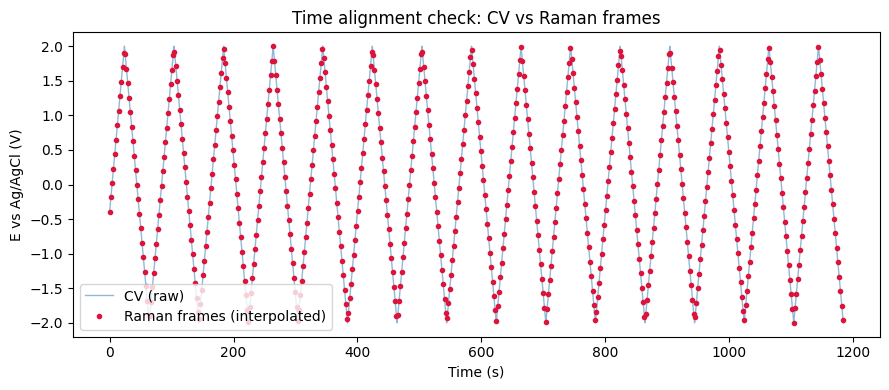

In [7]:
## This plot os to quickly check that the Raman aquisition and the CV timestamps are alligned

plot_time_alignment(m22_nanostructuring_NaCl["cv"], t_raman_m22_nanostructuring_NaCl, E_interp_m22_nanostructuring_NaCl)
plot_time_alignment(m27_nanostructuring_KI["cv"], t_raman_m27_nanostructuring_KI, E_interp_m27_nanostructuring_KI)

### Quick look at the raw spectra

Browse the raw spectra before fitting, to sanity-check peak shapes/positions and pick sensible `REGION`/initial guesses below.

In [70]:
spectrum_browser(x_m22_nanostructuring_NaCl, Y_m22_nanostructuring_NaCl)
#spectrum_browser(x_m27_nanostructuring_KI, Y_m27_nanostructuring_KI)

interactive(children=(IntSlider(value=0, description='Spectrum', max=599), Output()), _dom_classes=('widget-in…

### Peak deconvolution

Fit a two-Gaussian + linear-baseline model to the chosen spectral `REGION`, where
- `REGION`: spectral window (cm⁻¹) used for the fit.
- `CENTERS_GUESS`, `SIGMAS_GUESS`: initial guesses for each peak's center and width (sigma, cm⁻¹).
- `LOWER_BOUNDS`, `UPPER_BOUNDS`: fit bounds, in parameter order (A1, x01, s1, A2, x02, s2, c0, c1) — amplitude, center and sigma for each peak, then the linear baseline intercept/slope (`c0`, `c1`, referenced to the region midpoint).

In [17]:
# --- Spectral region and initial guesses: edit these for a different peak / measurement ---
#This cell deconvolutes the 115 - 195 cm-1 region of the Raman spectra for the m22_nanostructuring_NaCl measurement, which contains the CuCl and Cu2O peaks.

REGION_m22 = (115, 195)             # cm-1 window to fit
CENTERS_GUESS_m22 = (135.0, 160.0)  # initial guess: peak centers (cm-1)
SIGMAS_GUESS_m22 = (4.0, 8.0)       # initial guess: peak widths, sigma (cm-1)

#                            A1     x01    s1     A2      x02   s2     c0    c1
LOWER_BOUNDS_m22 = np.array([0,    121,   1.5,   0,      152,  3.0,  -50,  -2])
UPPER_BOUNDS_m22 = np.array([np.inf, 153, 8.0, np.inf,   182, 16.0,   80,   2])

PEAK1_LABEL_m22, PEAK1_NAME_m22 = "peak1", "Cu$_{2}$O 140 cm$^{-1}$"
PEAK2_LABEL_m22, PEAK2_NAME_m22 = "peak2", "CuCl 158 cm$^{-1}$"

fit_m22_nanostructuring_NaCl = fit_double_gaussian_series(
    x_m22_nanostructuring_NaCl, Y_m22_nanostructuring_NaCl, region=REGION_m22,
    centers_guess=CENTERS_GUESS_m22, sigmas_guess=SIGMAS_GUESS_m22,
    lower_bounds=LOWER_BOUNDS_m22, upper_bounds=UPPER_BOUNDS_m22,
)
 
results_m22 = deconvolution_results_to_df(
    fit_m22_nanostructuring_NaCl, t_raman_m22_nanostructuring_NaCl, E_interp_m22_nanostructuring_NaCl, i_interp_m22_nanostructuring_NaCl,
    peak1_label=PEAK1_LABEL_m22, peak2_label=PEAK2_LABEL_m22,)

# Export the results to a CSV file for record-keeping. 
#results_m22.to_csv("m22_nanostructuring_NaCl_raman_peak_tracking.csv", index=False)

results_m22.head()

,time_s,potential_V,current_A,peak1_center_cm-1,peak1_height,peak1_sigma_cm-1,peak1_FWHM_cm-1,peak1_area,peak2_center_cm-1,peak2_height,peak2_sigma_cm-1,peak2_FWHM_cm-1,peak2_area,baseline_c0,baseline_c1,R2
0,0.000000,-0.204501,-0.040451,147.251730,62.446834,2.771966,6.527482,433.898678,152.518531,41.873552,6.547428,15.418014,687.227380,8.772688,-0.037395,0.835762
1,2.071918,0.002002,4.055648,147.425303,489.067837,2.521509,5.937699,3091.145887,152.000000,1342.797695,16.000000,37.677121,53854.314711,4.808140,-2.000000,0.970815
2,4.162521,0.211211,13.222230,130.177946,1420.847158,8.000000,18.838560,28492.285279,153.078221,4327.019558,16.000000,37.677121,173539.673121,-26.739742,2.000000,0.991048
3,6.256962,0.420749,21.304733,132.117815,1735.323129,8.000000,18.838560,34798.480167,155.523833,3791.716292,13.200582,31.084996,125463.921048,-50.000000,-2.000000,0.987014
4,8.350927,0.630383,30.375246,132.162879,1774.188027,8.000000,18.838560,35577.838988,155.263623,3809.833495,13.000105,30.612908,124148.874622,-11.439201,-2.000000,0.985973


In [18]:
#This cell deconvolutes the 115 - 195 cm-1 region of the Raman spectra for the m27_nanostructuring_KI measurement, which contains the CuI and Cu2O peaks.

REGION_m27_1 = (115, 195)             # cm-1 window to fit
CENTERS_GUESS_m27_1 = (124.5, 150.0)  # initial guess: peak centers (cm-1)
SIGMAS_GUESS_m27_1 = (4.0, 8.0)       # initial guess: peak widths, sigma (cm-1)

#                            A1     x01    s1     A2      x02   s2     c0    c1
LOWER_BOUNDS_m27_1 = np.array([0,    121,   1.5,   0,      142,  3.0,  -50,  -2])
UPPER_BOUNDS_m27_1 = np.array([np.inf, 133, 8.0, np.inf,   162, 16.0,   80,   2])

PEAK1_LABEL_m27_1, PEAK1_NAME_m27_1 = "peak1", "CuI 123 cm$^{-1}$"
PEAK2_LABEL_m27_1, PEAK2_NAME_m27_1 = "peak2", "Cu$_{2}$O 146 cm$^{-1}$"

fit_m27_nanostructuring_KI_1 = fit_double_gaussian_series(
    x_m27_nanostructuring_KI, Y_m27_nanostructuring_KI, region=REGION_m27_1,
    centers_guess=CENTERS_GUESS_m27_1, sigmas_guess=SIGMAS_GUESS_m27_1,
    lower_bounds=LOWER_BOUNDS_m27_1, upper_bounds=UPPER_BOUNDS_m27_1,
)
 
results_m27_1 = deconvolution_results_to_df(
    fit_m27_nanostructuring_KI_1, t_raman_m27_nanostructuring_KI, E_interp_m27_nanostructuring_KI, i_interp_m27_nanostructuring_KI,
    peak1_label=PEAK1_LABEL_m27_1, peak2_label=PEAK2_LABEL_m27_1,)

# Export the results to a CSV file for record-keeping. 
#results_m27_1.to_csv("m27_nanostructuring_KI_raman_peak_tracking_region_1.csv", index=False)

results_m27_1.head()

,time_s,potential_V,current_A,peak1_center_cm-1,peak1_height,peak1_sigma_cm-1,peak1_FWHM_cm-1,peak1_area,peak2_center_cm-1,peak2_height,peak2_sigma_cm-1,peak2_FWHM_cm-1,peak2_area,baseline_c0,baseline_c1,R2
0,0.000000,-0.394831,0.039598,126.591870,47.363613,4.666618,10.989047,554.034810,154.446026,114.735362,15.040759,35.418281,4325.705749,-4.400278,0.003425,0.945601
1,2.075964,-0.187283,5.637524,125.872127,162.326519,4.860684,11.446036,1977.774630,149.350839,522.610070,16.000000,37.677121,20959.826857,-46.816749,0.989267,0.973263
2,4.170984,0.022247,14.373554,124.467790,280.075263,2.864536,6.745467,2011.031939,146.519835,974.514091,15.834859,37.288243,38680.515295,-50.000000,1.238905,0.982041
3,6.263393,0.231532,21.134743,123.358121,366.139165,3.022343,7.117073,2773.830022,146.823265,994.005894,14.711938,34.643965,36656.311902,-50.000000,1.179859,0.984954
4,8.357977,0.441055,27.714628,123.223226,476.029548,2.853099,6.718534,3404.400462,145.929356,1063.535062,16.000000,37.677121,42654.192939,-50.000000,1.713425,0.980514


In [19]:
#Given that the signal at ~150 cm-1 is still a convoluted signal from Cu2O T_1u (TO-LO) and gamma-CuI (LO), a second region is selected to deconvolute the Cu2O signal.
#Thus, this cell deconvolutes the 200 - 265 cm-1 region of the Raman spectra for the m27_nanostructuring_KI measurement, which contains the CuCl and Cu2O peaks.

REGION_m27_2 = (200, 265)             # cm-1 window to fit
CENTERS_GUESS_m27_2 = (215.0, 238.0)  # initial guess: peak centers (cm-1)
SIGMAS_GUESS_m27_2 = (4.0, 8.0)       # initial guess: peak widths, sigma (cm-1)

#                            A1     x01    s1     A2      x02   s2     c0    c1
LOWER_BOUNDS_m27_2 = np.array([0,    210,   1.5,   0,      215,  3.0,  -50,  -2])
UPPER_BOUNDS_m27_2 = np.array([np.inf, 225, 8.0, np.inf,   250, 16.0,   80,   2])

PEAK1_LABEL_m27_2, PEAK1_NAME_m27_2 = "peak1", "Cu$_{2}$O 215 cm$^{-1}$"
PEAK2_LABEL_m27_2, PEAK2_NAME_m27_2 = "peak2", "CuI 238 cm$^{-1}$"

fit_m27_nanostructuring_KI_2 = fit_double_gaussian_series(
    x_m27_nanostructuring_KI, Y_m27_nanostructuring_KI, region=REGION_m27_2,
    centers_guess=CENTERS_GUESS_m27_2, sigmas_guess=SIGMAS_GUESS_m27_2,
    lower_bounds=LOWER_BOUNDS_m27_2, upper_bounds=UPPER_BOUNDS_m27_2,
)
 
results_m27_2 = deconvolution_results_to_df(
    fit_m27_nanostructuring_KI_2, t_raman_m27_nanostructuring_KI, E_interp_m27_nanostructuring_KI, i_interp_m27_nanostructuring_KI,
    peak1_label=PEAK1_LABEL_m27_2, peak2_label=PEAK2_LABEL_m27_2,)

# Export the results to a CSV file for record-keeping. 
#results_m27_2.to_csv("m27_nanostructuring_KI_raman_peak_tracking_region_2.csv", index=False)

results_m27_2.head()

,time_s,potential_V,current_A,peak1_center_cm-1,peak1_height,peak1_sigma_cm-1,peak1_FWHM_cm-1,peak1_area,peak2_center_cm-1,peak2_height,peak2_sigma_cm-1,peak2_FWHM_cm-1,peak2_area,baseline_c0,baseline_c1,R2
0,0.000000,-0.394831,0.039598,224.822768,16.849453,1.500000,3.532230,63.352973,215.683429,31.491778,16.000000,37.677121,1263.010918,-7.619699,0.184595,0.744672
1,2.075964,-0.187283,5.637524,224.666365,65.619006,1.739388,4.095946,286.098862,215.000000,187.421569,15.978985,37.627634,7506.866496,-48.532572,1.445927,0.846078
2,4.170984,0.022247,14.373554,210.000000,110.965589,8.000000,18.838560,2225.195854,223.455182,199.392141,8.298465,19.541391,4147.588986,-10.200107,-0.010442,0.830589
3,6.263393,0.231532,21.134743,210.000000,67.929475,8.000000,18.838560,1362.191547,222.449450,208.230575,9.294254,21.886295,4851.197623,-3.687772,-0.073725,0.849367
4,8.357977,0.441055,27.714628,210.000000,148.226489,8.000000,18.838560,2972.389660,223.992247,206.719355,8.306732,19.560858,4304.287383,-22.603332,0.886922,0.894882


### Fit diagnostics

Check the fit quality and whether either peak's center is pinned at its bound — if a large fraction is pinned, the true peak most likely sits outside the current `CENTERS_GUESS`/bounds for this measurement, and they should be revisited above.

In [20]:
#Fit check for the m22_nanostructuring_NaCl measurement
n = len(fit_m22_nanostructuring_NaCl["r2_values"])
print(f"R² across {n} spectra: mean={np.nanmean(fit_m22_nanostructuring_NaCl['r2_values']):.3f}, "
      f"median={np.nanmedian(fit_m22_nanostructuring_NaCl['r2_values']):.3f}, min={np.nanmin(fit_m22_nanostructuring_NaCl['r2_values']):.3f}")

at_ub1 = np.isclose(results_m22[f"{PEAK1_LABEL_m22}_center_cm-1"], UPPER_BOUNDS_m22[1], atol=0.05)
at_lb1 = np.isclose(results_m22[f"{PEAK1_LABEL_m22}_center_cm-1"], LOWER_BOUNDS_m22[1], atol=0.05)
at_ub2 = np.isclose(results_m22[f"{PEAK2_LABEL_m22}_center_cm-1"], UPPER_BOUNDS_m22[4], atol=0.05)
at_lb2 = np.isclose(results_m22[f"{PEAK2_LABEL_m22}_center_cm-1"], LOWER_BOUNDS_m22[4], atol=0.05)

print(f"{PEAK1_NAME_m22}: pinned at upper bound in {at_ub1.sum()}/{n}, at lower bound in {at_lb1.sum()}/{n}")
print(f"{PEAK2_NAME_m22}: pinned at upper bound in {at_ub2.sum()}/{n}, at lower bound in {at_lb2.sum()}/{n}")

R² across 600 spectra: mean=0.914, median=0.967, min=0.218
Cu$_{2}$O 140 cm$^{-1}$: pinned at upper bound in 0/600, at lower bound in 0/600
CuCl 158 cm$^{-1}$: pinned at upper bound in 0/600, at lower bound in 29/600


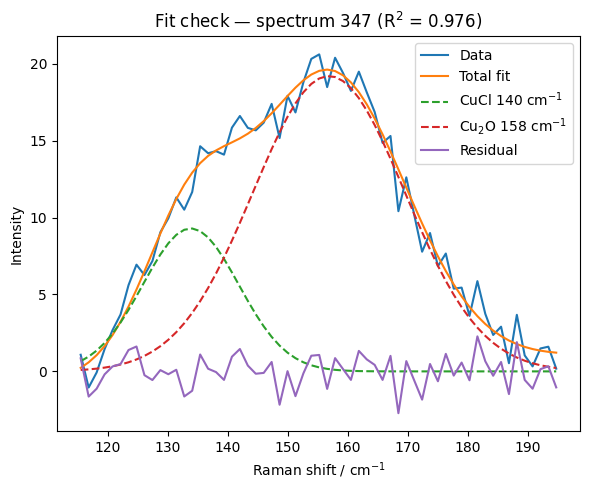

In [88]:
plot_fit_check(fit_m22_nanostructuring_NaCl, index=347, peak1_label=PEAK1_NAME_m22, peak2_label=PEAK2_NAME_m22)

In [13]:
#Fit check for the m27_nanostructuring_KI measurement in the region 1 (115 - 195 cm-1)

n = len(fit_m27_nanostructuring_KI_1["r2_values"])
print(f"R² across {n} spectra: mean={np.nanmean(fit_m27_nanostructuring_KI_1['r2_values']):.3f}, "
      f"median={np.nanmedian(fit_m27_nanostructuring_KI_1['r2_values']):.3f}, min={np.nanmin(fit_m27_nanostructuring_KI_1['r2_values']):.3f}")

at_ub1 = np.isclose(results_m27_1[f"{PEAK1_LABEL_m27_1}_center_cm-1"], UPPER_BOUNDS_m27_1[1], atol=0.05)
at_lb1 = np.isclose(results_m27_1[f"{PEAK1_LABEL_m27_1}_center_cm-1"], LOWER_BOUNDS_m27_1[1], atol=0.05)
at_ub2 = np.isclose(results_m27_1[f"{PEAK2_LABEL_m27_1}_center_cm-1"], UPPER_BOUNDS_m27_1[4], atol=0.05)
at_lb2 = np.isclose(results_m27_1[f"{PEAK2_LABEL_m27_1}_center_cm-1"], LOWER_BOUNDS_m27_1[4], atol=0.05)

print(f"{PEAK1_NAME_m27_1}: pinned at upper bound in {at_ub1.sum()}/{n}, at lower bound in {at_lb1.sum()}/{n}")
print(f"{PEAK2_NAME_m27_1}: pinned at upper bound in {at_ub2.sum()}/{n}, at lower bound in {at_lb2.sum()}/{n}")

R² across 600 spectra: mean=0.990, median=0.991, min=0.946
CuI 123 cm$^{-1}$: pinned at upper bound in 28/600, at lower bound in 58/600
Cu$_{2}$O 146 cm$^{-1}$: pinned at upper bound in 0/600, at lower bound in 20/600


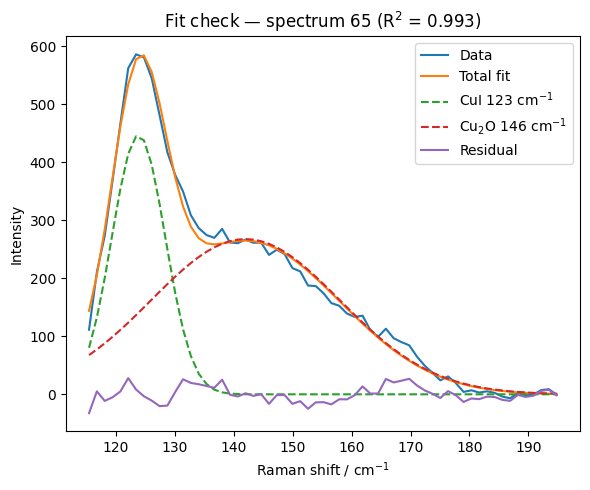

In [14]:
plot_fit_check(fit_m27_nanostructuring_KI_1, index=65, peak1_label=PEAK1_NAME_m27_1, peak2_label=PEAK2_NAME_m27_1)

In [15]:
#Fit check for the m27_nanostructuring_KI measurement in the region 2 (200 - 265 cm-1)

n = len(fit_m27_nanostructuring_KI_2["r2_values"])
print(f"R² across {n} spectra: mean={np.nanmean(fit_m27_nanostructuring_KI_2['r2_values']):.3f}, "
      f"median={np.nanmedian(fit_m27_nanostructuring_KI_2['r2_values']):.3f}, min={np.nanmin(fit_m27_nanostructuring_KI_2['r2_values']):.3f}")

at_ub1 = np.isclose(results_m27_2[f"{PEAK1_LABEL_m27_2}_center_cm-1"], UPPER_BOUNDS_m27_2[1], atol=0.05)
at_lb1 = np.isclose(results_m27_2[f"{PEAK1_LABEL_m27_2}_center_cm-1"], LOWER_BOUNDS_m27_2[1], atol=0.05)
at_ub2 = np.isclose(results_m27_2[f"{PEAK2_LABEL_m27_2}_center_cm-1"], UPPER_BOUNDS_m27_2[4], atol=0.05)
at_lb2 = np.isclose(results_m27_2[f"{PEAK2_LABEL_m27_2}_center_cm-1"], LOWER_BOUNDS_m27_2[4], atol=0.05)

print(f"{PEAK1_NAME_m27_2}: pinned at upper bound in {at_ub1.sum()}/{n}, at lower bound in {at_lb1.sum()}/{n}")
print(f"{PEAK2_NAME_m27_2}: pinned at upper bound in {at_ub2.sum()}/{n}, at lower bound in {at_lb2.sum()}/{n}")

R² across 600 spectra: mean=0.944, median=0.968, min=0.527
Cu$_{2}$O 215 cm$^{-1}$: pinned at upper bound in 0/600, at lower bound in 15/600
CuI 238 cm$^{-1}$: pinned at upper bound in 0/600, at lower bound in 1/600


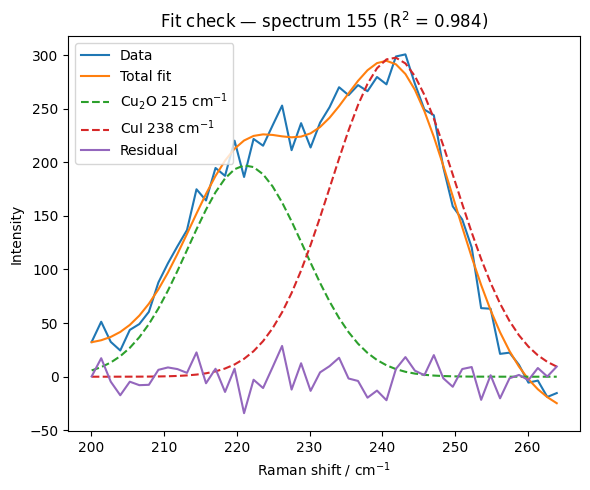

In [16]:
plot_fit_check(fit_m27_nanostructuring_KI_2, index=155, peak1_label=PEAK1_NAME_m27_2, peak2_label=PEAK2_NAME_m27_2)

### One panel figure (nanostructuration) for the main text

### Figure 8

C:\Users\cmesa\AppData\Local\Temp\ipykernel_31692\2891012013.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


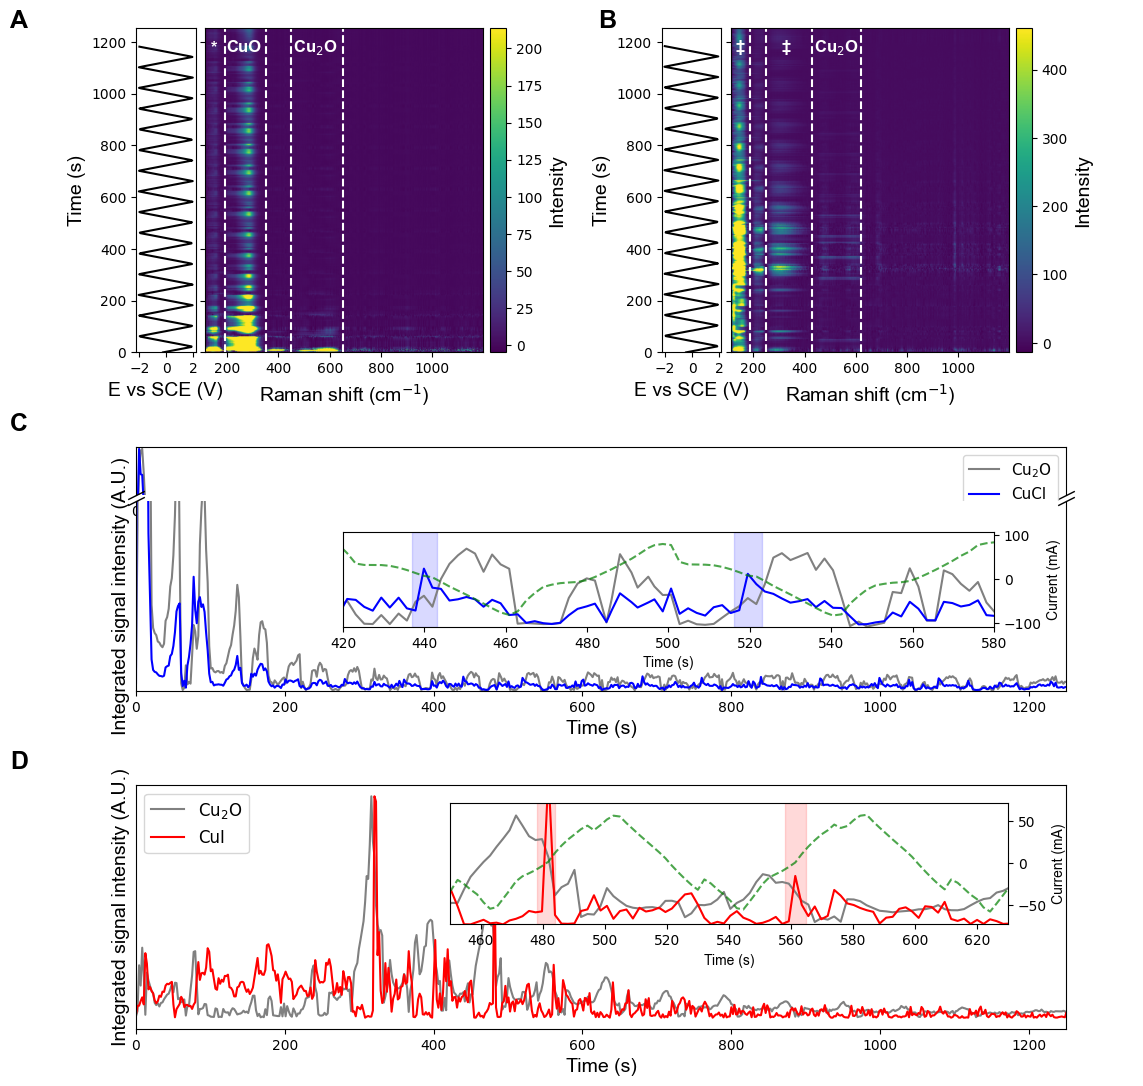

In [21]:
# This cell generates the Figure 8 of the main text, which compares the Raman spectra as function of time (i.e., applied potential) as heatmaps (A and B) for the two electrolyte compositions
# Furthermore, figures C and D show the evolution of the CuCl and Cu2O peaks, and CuI and Cu2O peaks, intensities, respectively, as function of time (i.e., applied potential) for the two electrolyte compositions.

E_calib = 0.044 #V, calibration offset to convert the Ag/AgCl reference potential to the SCE scale

fig = plt.figure(figsize=(12, 13))

gs = GridSpec(3, 2, figure=fig, height_ratios=[1, 0.75, 0.75], width_ratios=[1, 1], hspace=0.35, wspace=0.30)

#############################     Figure 8A     ##########################################
ax1_a = gs[0,0].subgridspec(1,2, width_ratios=[0.8, 4.5], wspace=0.05)

vmin_m22 = np.percentile(Y_m22_nanostructuring_NaCl, 1)
vmax_m22 = np.percentile(Y_m22_nanostructuring_NaCl, 99)

ax1_ec22 = fig.add_subplot(ax1_a[0])
ax1_ec22.plot(E_interp_m22_nanostructuring_NaCl - E_calib, t_raman_m22_nanostructuring_NaCl, color="black")
ax1_ec22.set_xlabel("E vs SCE (V)", fontsize=14, family='Arial')
ax1_ec22.set_ylabel("Time (s)", fontsize=14, family='Arial')
ax1_ec22.invert_yaxis()
ax1_r22  = fig.add_subplot(ax1_a[1], sharey=ax1_ec22)
im_22 = ax1_r22.imshow(Y_m22_nanostructuring_NaCl, aspect="auto", origin="lower", extent=[x_m22_nanostructuring_NaCl.min(), x_m22_nanostructuring_NaCl.max(), t_raman_m22_nanostructuring_NaCl.min(), t_raman_m22_nanostructuring_NaCl.max()], vmin=vmin_m22, vmax=vmax_m22)
ax1_r22.plot([190, 190], [0, 1250], color='white', linestyle='--', lw=1.5)
ax1_r22.plot([350, 350], [0, 1250], color='white', linestyle='--', lw=1.5)
ax1_r22.plot([450, 450], [0, 1250], color='white', linestyle='--', lw=1.5)
ax1_r22.plot([650, 650], [0, 1250], color='white', linestyle='--', lw=1.5)
ax1_r22.text(135, 1180, "*", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax1_r22.text(198, 1180, "CuO", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax1_r22.text(455, 1180, "Cu$_2$O", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax1_r22.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family='Arial')
plt.setp(ax1_r22.get_yticklabels(), visible=False)
cbar22 = fig.colorbar(im_22, ax=ax1_r22, pad=0.02)
cbar22.set_label("Intensity", fontsize=14, family='Arial')

#############################     Figure 8B     ##########################################
ax1_b = gs[0,1].subgridspec(1,2, width_ratios=[0.8, 4.5], wspace=0.05)

vmin_m27 = np.percentile(Y_m27_nanostructuring_KI, 1)
vmax_m27 = np.percentile(Y_m27_nanostructuring_KI, 99)

ax1_ec27 = fig.add_subplot(ax1_b[0])
ax1_ec27.plot(E_interp_m27_nanostructuring_KI - E_calib, t_raman_m27_nanostructuring_KI, color="black")
ax1_ec27.set_xlabel("E vs SCE (V)", fontsize=14, family='Arial')
ax1_ec27.set_ylabel("Time (s)", fontsize=14, family='Arial')
ax1_ec27.invert_yaxis()
ax1_r27  = fig.add_subplot(ax1_b[1], sharey=ax1_ec27)
im_27 = ax1_r27.imshow(Y_m27_nanostructuring_KI, aspect="auto", origin="lower", extent=[x_m27_nanostructuring_KI.min(), x_m27_nanostructuring_KI.max(), t_raman_m27_nanostructuring_KI.min(), t_raman_m27_nanostructuring_KI.max()], vmin=vmin_m27, vmax=vmax_m27)
ax1_r27.plot([185, 185], [0, 1250], color='white', linestyle='--', lw=1.5)
ax1_r27.plot([250, 250], [0, 1250], color='white', linestyle='--', lw=1.5)
ax1_r27.plot([430, 430], [0, 1250], color='white', linestyle='--', lw=1.5)
ax1_r27.plot([620, 620], [0, 1250], color='white', linestyle='--', lw=1.5)
ax1_r27.text(130, 1180, "‡", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax1_r27.text(310, 1180, "‡", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax1_r27.text(435, 1180, "Cu$_2$O", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax1_r27.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family='Arial')
plt.setp(ax1_r27.get_yticklabels(), visible=False)
cbar27 = fig.colorbar(im_27, ax=ax1_r27, pad=0.02)
cbar27.set_label("Intensity", fontsize=14, family='Arial')

#############################     Figure 8C     ##########################################
ax1_c = gs[1, :].subgridspec(2, 1, height_ratios=[1, 4], hspace=0.05)
cu2o_norm_22 = results_m22["peak1_area"] / np.nanmax(results_m22["peak1_area"])
cucl_norm_22 = results_m22["peak2_area"] / np.nanmax(results_m22["peak2_area"])

ax1_c_top = fig.add_subplot(ax1_c[0])
ax1_c_bottom = fig.add_subplot(ax1_c[1], sharex=ax1_c_top)

for ax1 in (ax1_c_top, ax1_c_bottom):
    ax1.plot(t_raman_m22_nanostructuring_NaCl, cu2o_norm_22, color='grey',  label = 'Cu$_2$O')
    ax1.plot(t_raman_m22_nanostructuring_NaCl, cucl_norm_22, color='blue',  label = 'CuCl')

ax1_c_top.set_ylim(0.5, 1.02)
ax1_c_bottom.set_ylim(0, 0.1)
ax1_c_bottom.set_xlim(0, 1250)
ax1_c_top.spines['bottom'].set_visible(False)
ax1_c_bottom.spines['top'].set_visible(False)
ax1_c_top.tick_params(labeltop=False, bottom=False)
ax1_c_bottom.tick_params(top=False)

d = 0.5  
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12, linestyle="none", color='k', mec='k', mew=1, clip_on=False)
ax1_c_top.plot([0, 1], [0, 0], transform=ax1_c_top.transAxes, **kwargs)
ax1_c_bottom.plot([0, 1], [1, 1], transform=ax1_c_bottom.transAxes, **kwargs)

ax1_c_bottom.set_xlabel("Time (s)", fontsize=14, family='Arial')
ax1_c_bottom.set_ylabel("Integrated signal intensity (A.U.)", fontsize=14, family='Arial')
ax1_c_top.set_yticklabels([])
ax1_c_top.set_yticks([])
ax1_c_bottom.set_yticklabels([])
ax1_c_bottom.set_yticks([])
ax1_c_top.legend(fontsize=11, loc = 'upper right')

axins22 = inset_axes(ax1_c_bottom, width="70%", height="50%", loc="lower right", bbox_to_anchor=(-0.07,0.3,1,1), bbox_transform=ax1_c_bottom.transAxes)

axins22.plot(t_raman_m22_nanostructuring_NaCl, cu2o_norm_22, c = 'Grey',  label = 'Cu$_2$O')
axins22.plot(t_raman_m22_nanostructuring_NaCl, cucl_norm_22, c = 'Blue',  label = 'CuCl')
axins22.axvspan(437, 443, color='blue', alpha=0.15)
axins22.axvspan(516, 523, color='blue', alpha=0.15)
axins22b = axins22.twinx()
axins22b.plot(t_raman_m22_nanostructuring_NaCl, i_interp_m22_nanostructuring_NaCl, c='Green', ls='--', alpha=0.7, label='Current (mA)')
axins22b.set_ylabel("Current (mA)", family='Arial')

axins22.set_xlim(420, 580)   
axins22.set_ylim(0, 0.012)
axins22.set_yticklabels([])
axins22.set_yticks([])
axins22.set_xlabel("Time (s)", family='Arial')

#############################     Figure 8D     ##########################################
ax1_d = fig.add_subplot(gs[2, :])   
cuI_norm_27 = results_m27_1["peak1_area"] / np.nanmax(results_m27_1["peak1_area"])
cu2o_norm_27 = results_m27_2["peak1_area"] / np.nanmax(results_m27_2["peak1_area"])

ax1_d.plot(t_raman_m27_nanostructuring_KI, cu2o_norm_27, c = 'Grey',  label = 'Cu$_2$O')
ax1_d.plot(t_raman_m27_nanostructuring_KI, cuI_norm_27, c = 'Red',  label = 'CuI')

ax1_d.set_xlim(0, 1250)
ax1_d.set_xlabel("Time (s)", fontsize=14, family='Arial')
ax1_d.set_ylabel("Integrated signal intensity (A.U.)", fontsize=14, family='Arial')
ax1_d.set_yticklabels([])
ax1_d.set_yticks([])
ax1_d.legend(fontsize=12, loc = 'upper left')

axins27 = inset_axes(ax1_d, width="60%", height="50%", loc="lower right", bbox_to_anchor=(-0.055,0.4,1,1), bbox_transform=ax1_d.transAxes)

axins27.plot(t_raman_m27_nanostructuring_KI, cu2o_norm_27, c = 'Grey',  label = 'Cu$_2$O')
axins27.plot(t_raman_m27_nanostructuring_KI, cuI_norm_27, c = 'Red',  label = 'CuI')
axins27.axvspan(478, 484, color='Red', alpha=0.15)
axins27.axvspan(558, 565, color='Red', alpha=0.15)
axins27b = axins27.twinx()
axins27b.plot(t_raman_m27_nanostructuring_KI, i_interp_m27_nanostructuring_KI, c='Green', ls='--', alpha=0.7, label='Current (mA)')
axins27b.set_ylabel("Current (mA)", family='Arial')

axins27.set_xlim(450, 630)   
axins27.set_ylim(0, 0.6)
axins27.set_yticklabels([])
axins27.set_yticks([])
axins27.set_xlabel("Time (s)", family='Arial')

fig.text(0.02, 0.88, 'A', fontsize=18, family='Arial', fontweight='bold')
fig.text(0.51, 0.88, 'B', fontsize=18, family='Arial', fontweight='bold')
fig.text(0.02, 0.57, 'C', fontsize=18, family='Arial', fontweight='bold')
fig.text(0.02, 0.31, 'D', fontsize=18, family='Arial', fontweight='bold')

plt.tight_layout()
plt.savefig('Fig_8.png', dpi = 300, bbox_inches='tight')
plt.show()

### SI Figures

#### Panel showing representative Raman spectra and spectral assignments and gaussian fits
#### Panel showing supporting signal evolution intensities and heatmaps for the stripping experiments

### Representative Raman spectra and spectral assignments as well as fit examples and residuals - Figure S7

C:\Users\cmesa\AppData\Local\Temp\ipykernel_31692\3753760802.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


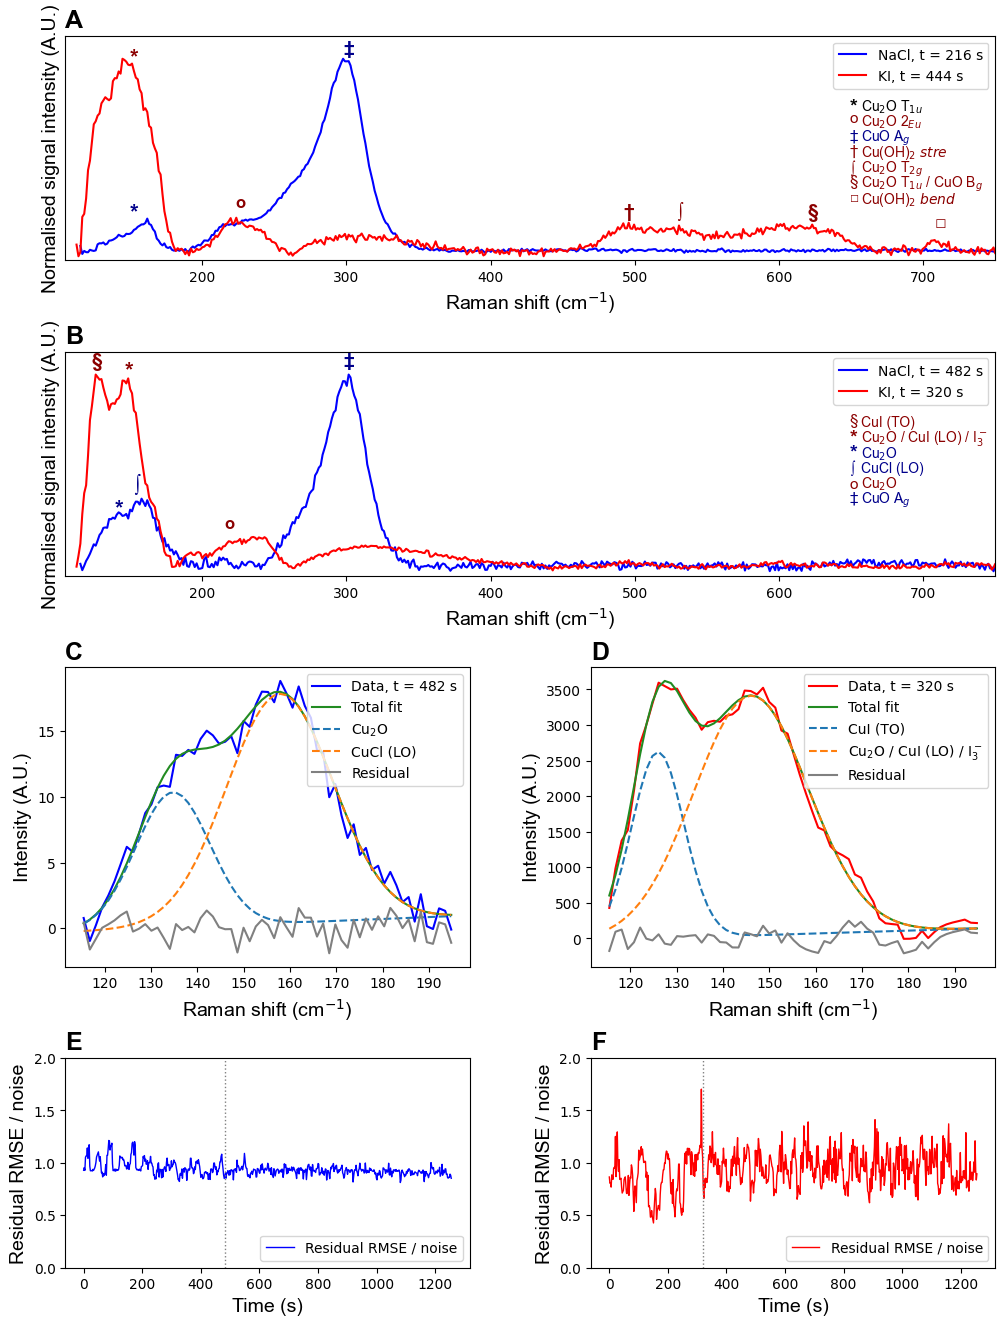

In [43]:
# This cell generates the Figure S7 of the supporting information, which shows Raman spectra at different times comparing the two electrolyte compositions and assigning the observed peaks
# to the corresponding vibrations from literature for the copper oxides (A) and copper halides (B). The spectra are normalized to their maximum intensities.
# Furthermore, figures C and D show the fitting results of the spectra shown in figure B, and finally, figures E and F show the residuals (RMSE) to noise ratio of the fitting results for the two electrolyte compositions.

fig = plt.figure(figsize=(12, 16))

gs_SI_ax2 = GridSpec(4, 2, figure=fig, height_ratios=[0.75, 0.75, 1, 0.7], width_ratios=[1, 1], hspace=0.38, wspace=0.30)

#############################     Figure S7A     ##########################################
ax2_a = fig.add_subplot(gs_SI_ax2[0, :]) 

ax2_a.plot(x_m22_nanostructuring_NaCl, Y_m22_nanostructuring_NaCl[103]/np.nanmax(Y_m22_nanostructuring_NaCl[103]), color='blue', label = f"NaCl, t = {t_raman_m22_nanostructuring_NaCl[103]:.0f} s")
ax2_a.plot(x_m27_nanostructuring_KI, Y_m27_nanostructuring_KI[212]/np.nanmax(Y_m27_nanostructuring_KI[212]), color='red', label = f"KI, t = {t_raman_m27_nanostructuring_KI[212]:.0f} s")

ax2_a.text(150, 0.2, "*", color='DarkBlue', va='center', fontsize=16, family='Arial', fontweight='bold')
ax2_a.text(150, 1.005, "*", color='DarkRed', va='center', fontsize=16, family='Arial', fontweight='bold')
ax2_a.text(223, 0.25, "o", color='DarkRed', va='center', fontsize=12, family='Arial', fontweight='bold')
ax2_a.text(298, 1.05, "‡", color='DarkBlue', va='center', fontsize=14, family='Arial', fontweight='bold')
ax2_a.text(492, 0.2, "†", color='DarkRed', va='center', fontsize=14, family='Arial', fontweight='bold')
ax2_a.text(530, 0.2, "∫", color='DarkRed', va='center', fontsize=14, family='Arial', fontweight='bold')
ax2_a.text(620, 0.2, "§", color='DarkRed', va='center', fontsize=14, family='Arial', fontweight='bold')
ax2_a.text(708, 0.15, "□", color='DarkRed', va='center', fontsize=14, family='Arial', fontweight='bold')

ax2_a.text(649, 0.75, "*", color='Black', va='center', fontsize=14, family='Arial', fontweight='bold')
ax2_a.text(657, 0.75, "Cu$_2$O T$_1$$_u$", color='Black', va='center', fontsize=10, family='Arial')
ax2_a.text(649, 0.69, "o", color='DarkRed', va='center', fontsize=11, family='Arial')
ax2_a.text(657, 0.67, "Cu$_2$O 2$_E$$_u$", color='DarkRed', va='center', fontsize=10, family='Arial')
ax2_a.text(649, 0.60, "‡", color='DarkBlue', va='center', fontsize=11, family='Arial')
ax2_a.text(657, 0.59, "CuO A$_g$", color='DarkBlue', va='center', fontsize=10, family='Arial')
ax2_a.text(649, 0.52, "†", color='DarkRed', va='center', fontsize=11, family='Arial')
ax2_a.text(657, 0.51, "Cu(OH)$_2$ $stre$", color='DarkRed', va='center', fontsize=10, family='Arial')
ax2_a.text(650, 0.43, "∫", color='DarkRed', va='center', fontsize=11, family='Arial')
ax2_a.text(657, 0.43, "Cu$_2$O T$_2$$_g$", color='DarkRed', va='center', fontsize=10, family='Arial')
ax2_a.text(649, 0.36, "§", color='DarkRed', va='center', fontsize=11, family='Arial')
ax2_a.text(657, 0.35, "Cu$_2$O T$_1$$_u$ / CuO B$_g$", color='DarkRed', va='center', fontsize=10, family='Arial')
ax2_a.text(649, 0.28, "□", color='DarkRed', va='center', fontsize=11, family='Arial')
ax2_a.text(657, 0.27, "Cu(OH)$_2$ $bend$", color='DarkRed', va='center', fontsize=10, family='Arial')

ax2_a.set_xlim(105, 750) 
ax2_a.set_ylim(-0.05, 1.12)   
ax2_a.set_yticklabels([])
ax2_a.set_yticks([])
ax2_a.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family='Arial')
ax2_a.set_ylabel("Normalised signal intensity (A.U.)", fontsize=14, family='Arial')
ax2_a.legend(fontsize=10, loc = 'upper right')
ax2_a.set_title('A', fontsize=18, loc='left', family='Arial', fontweight='bold')

#############################     Figure S7B     ##########################################
ax2_b = fig.add_subplot(gs_SI_ax2[1, :]) 

ax2_b.plot(x_m22_nanostructuring_NaCl, Y_m22_nanostructuring_NaCl[230]/np.nanmax(Y_m22_nanostructuring_NaCl[230]), color='blue', label = f"NaCl, t = {t_raman_m22_nanostructuring_NaCl[230]:.0f} s")
ax2_b.plot(x_m27_nanostructuring_KI, Y_m27_nanostructuring_KI[153]/np.nanmax(Y_m27_nanostructuring_KI[153]), color='red', label = f"KI, t = {t_raman_m27_nanostructuring_KI[153]:.0f} s")

ax2_b.text(123, 1.07, "§", color='DarkRed', va='center', fontsize=14, family='Arial', fontweight='bold')
ax2_b.text(146, 1.02, "*", color='DarkRed', va='center', fontsize=16, family='Arial', fontweight='bold')
ax2_b.text(139, 0.3, "*", color='DarkBlue', va='center', fontsize=16, family='Arial', fontweight='bold')
ax2_b.text(153, 0.42, "∫", color='DarkBlue', va='center', fontsize=15, family='Arial', fontweight='bold')
ax2_b.text(215, 0.22, "o", color='DarkRed', va='center', fontsize=12, family='Arial', fontweight='bold')
ax2_b.text(298, 1.07, "‡", color='DarkBlue', va='center', fontsize=14, family='Arial', fontweight='bold')

ax2_b.text(649, 0.76, "§", color='DarkRed', va='center', fontsize=11, family='Arial')
ax2_b.text(657, 0.75, "CuI (TO)", color='DarkRed', va='center', fontsize=10, family='Arial')
ax2_b.text(649, 0.67, "*", color='DarkRed', va='center', fontsize=14, family='Arial', fontweight='bold')
ax2_b.text(657, 0.67, "Cu$_2$O / CuI (LO) / I$_3^-$", color='DarkRed', va='center', fontsize=10, family='Arial')
ax2_b.text(649, 0.59, "*", color='DarkBlue', va='center', fontsize=14, family='Arial', fontweight='bold')
ax2_b.text(657, 0.59, "Cu$_2$O", color='DarkBlue', va='center', fontsize=10, family='Arial')
ax2_b.text(650, 0.51, "∫", color='DarkBlue', va='center', fontsize=11, family='Arial')
ax2_b.text(657, 0.51, "CuCl (LO)", color='DarkBlue', va='center', fontsize=10, family='Arial')
ax2_b.text(649, 0.43, "o", color='DarkRed', va='center', fontsize=11, family='Arial')
ax2_b.text(657, 0.43, "Cu$_2$O", color='DarkRed', va='center', fontsize=10, family='Arial')
ax2_b.text(649, 0.36, "‡", color='DarkBlue', va='center', fontsize=11, family='Arial')
ax2_b.text(657, 0.35, "CuO A$_g$", color='DarkBlue', va='center', fontsize=10, family='Arial')

ax2_b.set_xlim(105, 750)   
ax2_b.set_ylim(-0.05, 1.12)
ax2_b.set_yticklabels([])
ax2_b.set_yticks([])
ax2_b.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family='Arial')
ax2_b.set_ylabel("Normalised signal intensity (A.U.)", fontsize=14, family='Arial')
ax2_b.legend(fontsize=10, loc = 'upper right')
ax2_b.set_title('B', fontsize=18, loc='left', family='Arial', fontweight='bold')

#############################     Figure S7C     ##########################################

ax2_c = fig.add_subplot(gs_SI_ax2[2, 0])
xf, p1, p2, base = fit_m22_nanostructuring_NaCl["x_fit"], *fit_m22_nanostructuring_NaCl["fit_components"][230]
ax2_c.plot(xf, fit_m22_nanostructuring_NaCl["Y_fit"][230], color="blue", label=f"Data, t = {t_raman_m22_nanostructuring_NaCl[230]:.0f} s")
ax2_c.plot(xf, fit_m22_nanostructuring_NaCl["fit_curves"][230], color="forestgreen", label="Total fit")
ax2_c.plot(xf, p1 + base, "--", label="Cu$_2$O")
ax2_c.plot(xf, p2 + base, "--", label="CuCl (LO)")
ax2_c.plot(xf, fit_m22_nanostructuring_NaCl["Y_fit"][230] - fit_m22_nanostructuring_NaCl["fit_curves"][230], color="grey", label="Residual")
ax2_c.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family="Arial")
ax2_c.set_ylabel("Intensity (A.U.)", fontsize=14, family="Arial")
ax2_c.set_title('C', fontsize=18, loc='left', family='Arial', fontweight='bold')
ax2_c.legend(fontsize=10)

#############################     Figure S7D     ##########################################

ax2_c = fig.add_subplot(gs_SI_ax2[2, 1])
xf, p1, p2, base = fit_m27_nanostructuring_KI_1["x_fit"], *fit_m27_nanostructuring_KI_1["fit_components"][153]
ax2_c.plot(xf, fit_m27_nanostructuring_KI_1["Y_fit"][153], color="red", label=f"Data, t = {t_raman_m27_nanostructuring_KI[153]:.0f} s")
ax2_c.plot(xf, fit_m27_nanostructuring_KI_1["fit_curves"][153], color="forestgreen", label="Total fit")
ax2_c.plot(xf, p1 + base, "--", label="CuI (TO)")
ax2_c.plot(xf, p2 + base, "--", label="Cu$_2$O / CuI (LO) / I$_3^-$")
ax2_c.plot(xf, fit_m27_nanostructuring_KI_1["Y_fit"][153] - fit_m27_nanostructuring_KI_1["fit_curves"][153], color="grey", label="Residual")
ax2_c.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family="Arial")
ax2_c.set_ylabel("Intensity (A.U.)", fontsize=14, family="Arial")
ax2_c.set_title('D', fontsize=18, loc='left', family='Arial', fontweight='bold')
ax2_c.legend(fontsize=10)

#############################     Figure S7E / S7F : residual-to-noise ratio vs time     ##########################################

fits = {"E": (fit_m22_nanostructuring_NaCl, t_raman_m22_nanostructuring_NaCl, 230, "blue"),
        "F": (fit_m27_nanostructuring_KI_1, t_raman_m27_nanostructuring_KI,   153, "red")}

DETECTION_SIGMA = 3         

for col, (name, (fit, t, idx, colour)) in enumerate(fits.items()):
    ax = fig.add_subplot(gs_SI_ax2[3, col])
    resid = fit["Y_fit"] - fit["fit_curves"]
    n_pts = resid.shape[1]
    sigma = np.std(np.diff(fit["Y_fit"], axis=1), axis=1) / np.sqrt(2)         
    ratio = np.sqrt(np.nanmean(resid**2, axis=1)) / sigma                       
    ax.plot(t, ratio, color=colour, lw=1, label="Residual RMSE / noise")
    ax.axvline(t[idx], color="grey", ls=":", lw=1)                                                           
    ax.set_ylim(0, 2)
    ax.set_xlabel("Time (s)", fontsize=14, family="Arial")
    ax.set_ylabel("Residual RMSE / noise", fontsize=14, family="Arial")
    ax.set_title(f"{name}", fontsize=18, loc="left", family="Arial", fontweight="bold")
    ax.legend(fontsize=10, loc="lower right")

plt.tight_layout()
plt.savefig('Fig_S7.png', dpi = 300, bbox_inches='tight')
plt.show()

### Supporting signal evolution intensities and heatmaps for the stripping experiments - Figure S8

In [93]:
# first the stripping electrochemical and Raman data are loaded and correlated.
# The loaded data has the the same naming structure as the nanostructuring data:
# m_aa_nanostructuging_bb, where m stands for measurement number from the original dataset, aa is the measurement number and bb the electrolyte

m23_stripping_NaCl = load_and_correlate(
    cv_path="23_1M NaCl - Cu4_polished_CuCE_stripping_C01.mpt",
    raman_path="23_Stripping_NaCl_WiRE_treated.wdf",)

x_m23_stripping_NaCl, Y_m23_stripping_NaCl = m23_stripping_NaCl["x"], m23_stripping_NaCl["Y"]
t_raman_m23_stripping_NaCl, E_interp_m23_stripping_NaCl, i_interp_m23_stripping_NaCl = m23_stripping_NaCl["t_raman"], m23_stripping_NaCl["E_interp"], m23_stripping_NaCl["i_interp"]
m23_stripping_NaCl["extra_spectra"]

load_and_correlate: 3/50 Raman frames fall outside the CV recorded time range (CV: 0.0-50.6 s, Raman: 0.0-53.6 s). Their potential/current are set to NaN (see plot_time_alignment below).


C:\Users\cmesa\AppData\Local\Temp\ipykernel_23492\1425987870.py:35: ResourceWarning:

unclosed file <_io.BufferedReader name='23_Stripping_NaCl_WiRE_treated.wdf'>



{'n_frames': 50,
 'n_in_range': 47,
 'cv_t_range': (0.0, 50.56039881706238),
 'raman_t_range': (0.0, 53.58335304260254)}

In [94]:
m28_stripping_KI = load_and_correlate(
    cv_path="28_1M KI - Cu5_polished_CuCE_stripping_C01.mpt",
    raman_path="28_Stripping_KI_WiRE_treated.wdf",)

x_m28_stripping_KI, Y_m28_stripping_KI = m28_stripping_KI["x"], m28_stripping_KI["Y"]
t_raman_m28_stripping_KI, E_interp_m28_stripping_KI, i_interp_m28_stripping_KI = m28_stripping_KI["t_raman"], m28_stripping_KI["E_interp"], m28_stripping_KI["i_interp"]
m28_stripping_KI["extra_spectra"]

load_and_correlate: 4/50 Raman frames fall outside the CV recorded time range (CV: 0.0-50.0 s, Raman: 0.0-53.6 s). Their potential/current are set to NaN (see plot_time_alignment below).


C:\Users\cmesa\AppData\Local\Temp\ipykernel_23492\1425987870.py:35: ResourceWarning:

unclosed file <_io.BufferedReader name='28_Stripping_KI_WiRE_treated.wdf'>



{'n_frames': 50,
 'n_in_range': 46,
 'cv_t_range': (0.0, 49.978598833084106),
 'raman_t_range': (0.0, 53.57934761047363)}

C:\Users\cmesa\AppData\Local\Temp\ipykernel_23492\1868534835.py:150: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



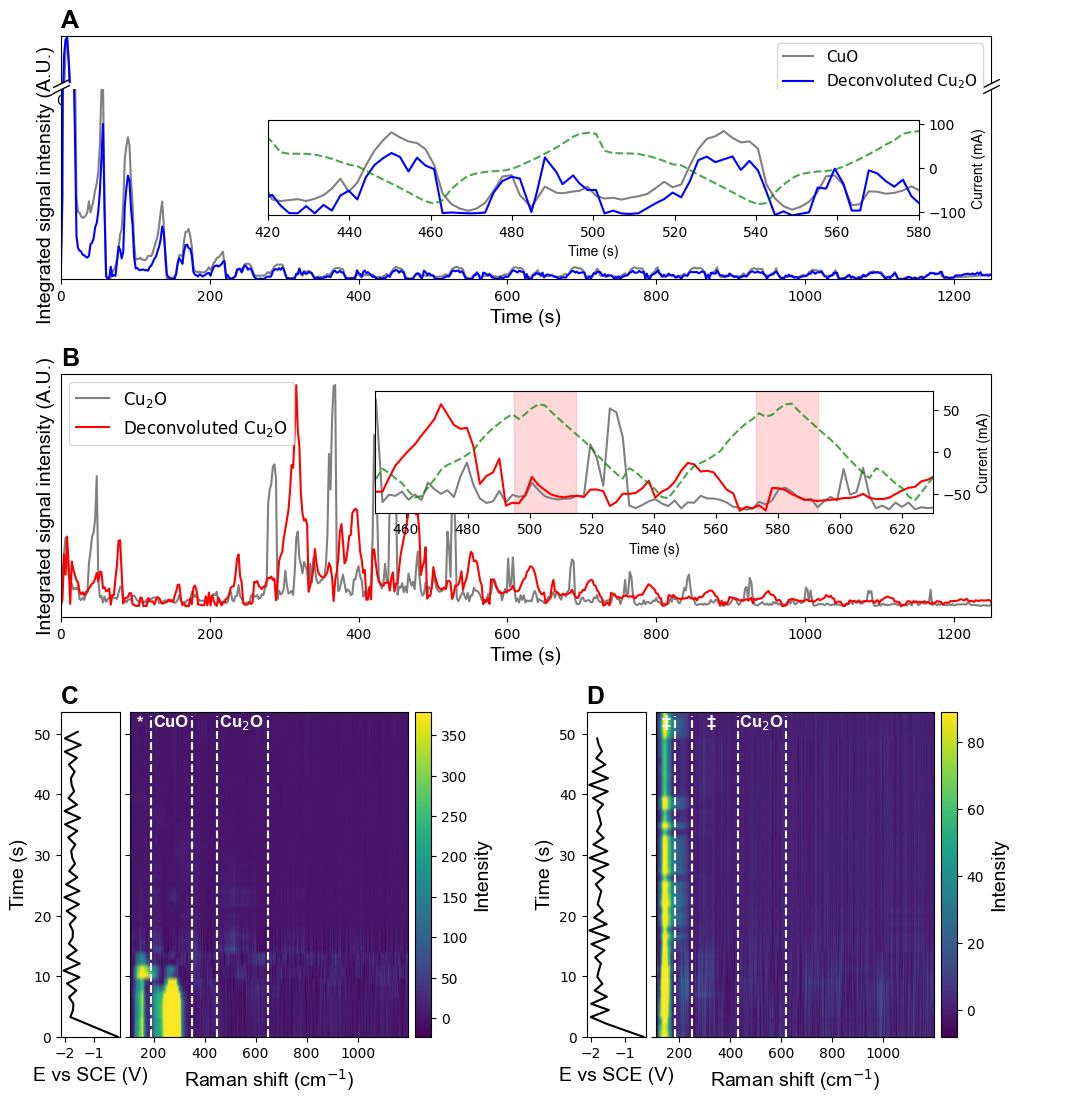

In [98]:
# This cell generates the Supplementary Figure 8, which compares supports the deconvolution results shown in Figure 8 of the main text, 
# by showing the evolution of the CuO at 295 cm-1 (calculated herein) and deconvoluted Cu2O peak intensities (Figure S8a) for the nanostructuring in NaCL, 
# and Cu2O at 520 cm-1 (calculated herein) and deconvoluted Cu2O peak intensities (Figure S8b) for the nanostructuring in KI, as function of time (i.e., applied potential).
# Heatmaps of the Raman spectra during the stripping process as function of time (i.e., applied potential) are also shown for the two electrolyte compositions (Figure S8c and S8d).

fig = plt.figure(figsize=(12, 13))

gs_SI_ax3 = GridSpec(3, 2, figure=fig, height_ratios=[0.75, 0.75, 1], width_ratios=[1, 1], hspace=0.35, wspace=0.30)

#############################     Figure S8A     ##########################################
ax3_a = gs_SI_ax3[0, :].subgridspec(2, 1, height_ratios=[1, 4], hspace=0.05)

mask_cuo = (x_m22_nanostructuring_NaCl >= 240) & (x_m22_nanostructuring_NaCl <= 340)
cuo_intensity = np.trapezoid(Y_m22_nanostructuring_NaCl[:, mask_cuo], x=x_m22_nanostructuring_NaCl[mask_cuo], axis=1)
cuo_norm_22 = cuo_intensity / np.nanmax(cuo_intensity)
cu2o_norm_22 = results_m22["peak1_area"] / np.nanmax(results_m22["peak1_area"])

ax3_a_top = fig.add_subplot(ax3_a[0])
ax3_a_bottom = fig.add_subplot(ax3_a[1], sharex=ax3_a_top)

for ax3 in (ax3_a_top, ax3_a_bottom):
    ax3.plot(t_raman_m22_nanostructuring_NaCl, cuo_norm_22, color='grey',  label = 'CuO')
    ax3.plot(t_raman_m22_nanostructuring_NaCl, cu2o_norm_22, color='blue',  label = 'Deconvoluted Cu$_2$O')

ax3_a_top.set_ylim(0.5, 1.02)
ax3_a_bottom.set_ylim(0, 0.2)
ax3_a_bottom.set_xlim(0, 1250)
ax3_a_top.spines['bottom'].set_visible(False)
ax3_a_bottom.spines['top'].set_visible(False)
ax3_a_top.tick_params(labeltop=False, bottom=False)
ax3_a_bottom.tick_params(top=False)

d = 0.5  
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12, linestyle="none", color='k', mec='k', mew=1, clip_on=False)
ax3_a_top.plot([0, 1], [0, 0], transform=ax3_a_top.transAxes, **kwargs)
ax3_a_bottom.plot([0, 1], [1, 1], transform=ax3_a_bottom.transAxes, **kwargs)

ax3_a_bottom.set_xlabel("Time (s)", fontsize=14, family='Arial')
ax3_a_bottom.set_ylabel("Integrated signal intensity (A.U.)", fontsize=14, family='Arial')
ax3_a_top.set_yticklabels([])
ax3_a_top.set_yticks([])
ax3_a_bottom.set_yticklabels([])
ax3_a_bottom.set_yticks([])
ax3_a_top.legend(fontsize=11, loc = 'upper right')
ax3_a_top.set_title('A', fontsize=18, loc='left', family='Arial', fontweight='bold')

axins22_SI = inset_axes(ax3_a_bottom, width="70%", height="50%", loc="lower right", bbox_to_anchor=(-0.07,0.3,1,1), bbox_transform=ax3_a_bottom.transAxes)

axins22_SI.plot(t_raman_m22_nanostructuring_NaCl, cuo_norm_22, c = 'Grey',  label = 'CuO')
axins22_SI.plot(t_raman_m22_nanostructuring_NaCl, cu2o_norm_22, c = 'Blue',  label = 'Deconvoluted Cu$_2$O')
axins22b_SI = axins22_SI.twinx()
axins22b_SI.plot(t_raman_m22_nanostructuring_NaCl, i_interp_m22_nanostructuring_NaCl, c='Green', ls='--', alpha=0.7, label='Current (mA)')
axins22b_SI.set_ylabel("Current (mA)", family='Arial')

axins22_SI.set_xlim(420, 580)   
axins22_SI.set_ylim(0, 0.015)
axins22_SI.set_yticklabels([])
axins22_SI.set_yticks([])
axins22_SI.set_xlabel("Time (s)", family='Arial')

#############################     Figure S8B     ##########################################
ax3_b = fig.add_subplot(gs_SI_ax3[1, :])   

mask_cu2o = (x_m27_nanostructuring_KI >= 440) & (x_m27_nanostructuring_KI <= 670)
cu2o_intensity = np.trapezoid(Y_m27_nanostructuring_KI[:, mask_cu2o], x=x_m27_nanostructuring_KI[mask_cu2o], axis=1)
cu2o_norm_27 = cu2o_intensity / np.nanmax(cu2o_intensity)
cu2o_norm_27_deconv = results_m27_2["peak1_area"] / np.nanmax(results_m27_2["peak1_area"])

ax3_b.plot(t_raman_m27_nanostructuring_KI, cu2o_norm_27, c = 'Grey',  label = 'Cu$_2$O')
ax3_b.plot(t_raman_m27_nanostructuring_KI, cu2o_norm_27_deconv, c = 'red',  label = 'Deconvoluted Cu$_2$O')

ax3_b.set_xlim(0, 1250)
ax3_b.set_xlabel("Time (s)", fontsize=14, family='Arial')
ax3_b.set_ylabel("Integrated signal intensity (A.U.)", fontsize=14, family='Arial')
ax3_b.set_yticklabels([])
ax3_b.set_yticks([])
ax3_b.legend(fontsize=12, loc = 'upper left')
ax3_b.set_title('B', fontsize=18, loc='left', family='Arial', fontweight='bold')

axins27_SI = inset_axes(ax3_b, width="60%", height="50%", loc="lower right", bbox_to_anchor=(-0.055,0.4,1,1), bbox_transform=ax3_b.transAxes)

axins27_SI.plot(t_raman_m27_nanostructuring_KI, cu2o_norm_27, c = 'Grey',  label = 'Cu$_2$O')
axins27_SI.plot(t_raman_m27_nanostructuring_KI, cu2o_norm_27_deconv, c = 'red',  label = 'Deconvoluted Cu$_2$O')
axins27_SI.axvspan(495, 515, color='red', alpha=0.15)
axins27_SI.axvspan(573, 593, color='red', alpha=0.15)
axins27b_SI = axins27_SI.twinx()
axins27b_SI.plot(t_raman_m27_nanostructuring_KI, i_interp_m27_nanostructuring_KI, c='Green', ls='--', alpha=0.7, label='Current (mA)')
axins27b_SI.set_ylabel("Current (mA)", family='Arial')

axins27_SI.set_xlim(450, 630)   
axins27_SI.set_ylim(0, 0.6)
axins27_SI.set_yticklabels([])
axins27_SI.set_yticks([])
axins27_SI.set_xlabel("Time (s)", family='Arial')

#############################     Figure S8C     ##########################################
ax3_c = gs_SI_ax3[2,0].subgridspec(1,2, width_ratios=[0.8, 4.5], wspace=0.05)

vmin_23 = np.percentile(Y_m23_stripping_NaCl, 1)
vmax_23 = np.percentile(Y_m23_stripping_NaCl, 99)

ax3_ec23 = fig.add_subplot(ax3_c[0])
ax3_ec23.plot(E_interp_m23_stripping_NaCl - E_calib, t_raman_m23_stripping_NaCl, color="black")
ax3_ec23.set_xlabel("E vs SCE (V)", fontsize=14, family='Arial')
ax3_ec23.set_ylabel("Time (s)", fontsize=14, family='Arial')
ax3_ec23.set_title('C', fontsize=18, loc='left', family='Arial', fontweight='bold')
ax3_ec23.invert_yaxis()
ax3_r23  = fig.add_subplot(ax3_c[1], sharey=ax3_ec23)
im_23 = ax3_r23.imshow(Y_m23_stripping_NaCl, aspect="auto", origin="lower", extent=[x_m23_stripping_NaCl.min(), x_m23_stripping_NaCl.max(), 
                                                                    t_raman_m23_stripping_NaCl.min(), t_raman_m23_stripping_NaCl.max()], vmin=vmin_23, vmax=vmax_23)
ax3_r23.plot([190, 190], [0, 53], color='white', linestyle='--', lw=1.5)
ax3_r23.plot([350, 350], [0, 53], color='white', linestyle='--', lw=1.5)
ax3_r23.plot([450, 450], [0, 53], color='white', linestyle='--', lw=1.5)
ax3_r23.plot([650, 650], [0, 53], color='white', linestyle='--', lw=1.5)
ax3_r23.text(135, 52, "*", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax3_r23.text(198, 52, "CuO", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax3_r23.text(455, 52, "Cu$_2$O", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax3_r23.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family='Arial')
plt.setp(ax3_r23.get_yticklabels(), visible=False)
cbar23 = fig.colorbar(im_23, ax=ax3_r23, pad=0.02)
cbar23.set_label("Intensity", fontsize=14, family='Arial')

#############################     Figure S8D     ##########################################
ax3_d = gs_SI_ax3[2,1].subgridspec(1,2, width_ratios=[0.8, 4.5], wspace=0.05)

vmin_28 = np.percentile(Y_m28_stripping_KI, 1)
vmax_28 = np.percentile(Y_m28_stripping_KI, 99)

ax3_ec28 = fig.add_subplot(ax3_d[0])
ax3_ec28.plot(E_interp_m28_stripping_KI - E_calib, t_raman_m28_stripping_KI, color="black")
ax3_ec28.set_xlabel("E vs SCE (V)", fontsize=14, family='Arial')
ax3_ec28.set_ylabel("Time (s)", fontsize=14, family='Arial')
ax3_ec28.set_title('D', fontsize=18, loc='left', family='Arial', fontweight='bold')
ax3_ec28.invert_yaxis()
ax3_r28  = fig.add_subplot(ax3_d[1], sharey=ax3_ec28)
im_28 = ax3_r28.imshow(Y_m28_stripping_KI, aspect="auto", origin="lower", extent=[x_m28_stripping_KI.min(), x_m28_stripping_KI.max(), 
                                                                    t_raman_m28_stripping_KI.min(), t_raman_m28_stripping_KI.max()], vmin=vmin_28, vmax=vmax_28)
ax3_r28.plot([185, 185], [0, 53], color='white', linestyle='--', lw=1.5)
ax3_r28.plot([250, 250], [0, 53], color='white', linestyle='--', lw=1.5)
ax3_r28.plot([430, 430], [0, 53], color='white', linestyle='--', lw=1.5)
ax3_r28.plot([620, 620], [0, 53], color='white', linestyle='--', lw=1.5)
ax3_r28.text(130, 52, "‡", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax3_r28.text(310, 52, "‡", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax3_r28.text(435, 52, "Cu$_2$O", color='white', va='center', fontsize=12, family='Arial', fontweight='bold')
ax3_r28.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family='Arial')
plt.setp(ax3_r28.get_yticklabels(), visible=False)
cbar28 = fig.colorbar(im_28, ax=ax3_r28, pad=0.02)
cbar28.set_label("Intensity", fontsize=14, family='Arial')

plt.tight_layout()
plt.savefig('Fig_S8.png', dpi = 300, bbox_inches='tight')
plt.show()

### Characterisation of the electrolyte solution after the nanostructuring treatment - Figure S9

C:\Users\cmesa\AppData\Local\Temp\ipykernel_31692\695906367.py:3: ResourceWarning: unclosed file <_io.BufferedReader name='05_Electrolyte_1M_NaCl_WiRE_treated.wdf'>
  Electrolyte_NaCl = rp.load.renishaw("05_Electrolyte_1M_NaCl_WiRE_treated.wdf")
C:\Users\cmesa\AppData\Local\Temp\ipykernel_31692\695906367.py:4: ResourceWarning: unclosed file <_io.BufferedReader name='06_Electrolyte_1M_KI_WiRE_treated.wdf'>
  Electrolyte_KI = rp.load.renishaw("06_Electrolyte_1M_KI_WiRE_treated.wdf")


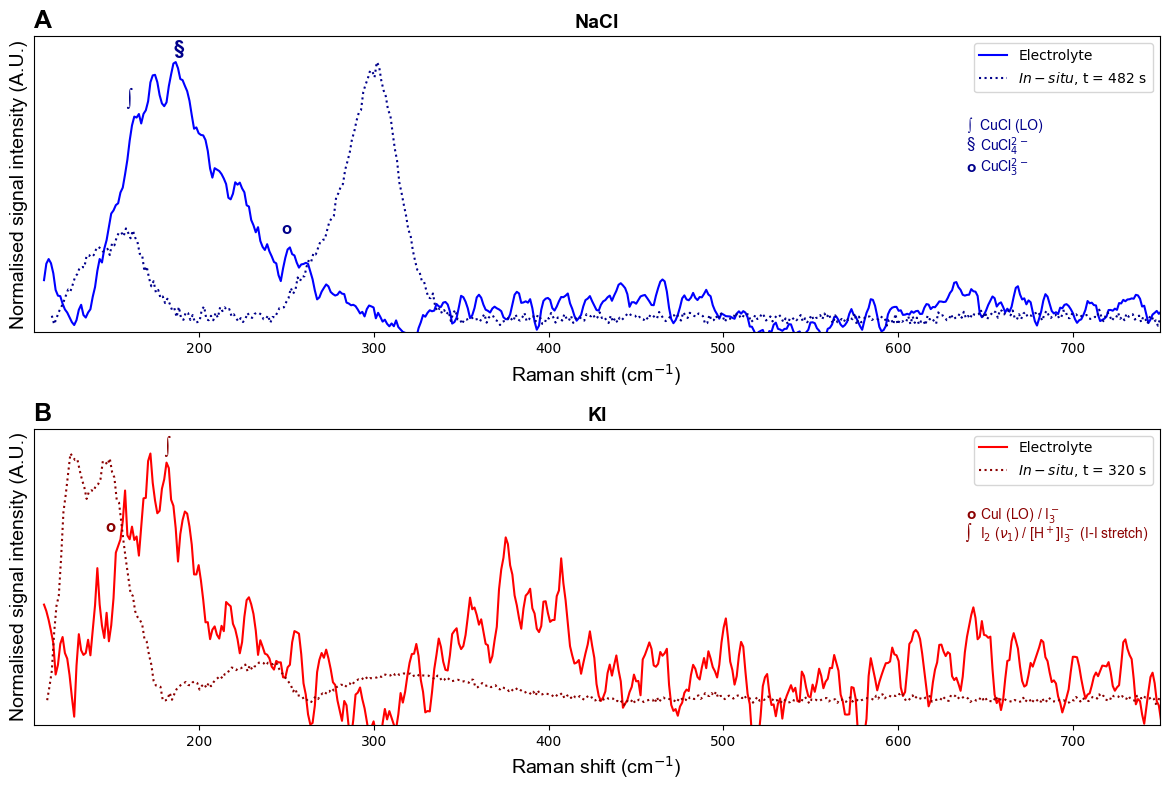

In [ ]:
# This cell loads and plots the pre-treated Raman spectra of the both electrolytes after the nanostructuring process.

Electrolyte_NaCl = rp.load.renishaw("05_Electrolyte_1M_NaCl_WiRE_treated.wdf")
Electrolyte_KI = rp.load.renishaw("06_Electrolyte_1M_KI_WiRE_treated.wdf")

x_NaCl = np.asarray(Electrolyte_NaCl.mean.spectral_axis, dtype=float)
Y_NaCl = np.asarray(Electrolyte_NaCl.mean.spectral_data, dtype=float)
x_KI = np.asarray(Electrolyte_KI.mean.spectral_axis, dtype=float)
Y_KI = np.asarray(Electrolyte_KI.mean.spectral_data, dtype=float)

fig, ax4 = plt.subplots(2, 1, figsize=(12, 8))

#############################     Figure S9A     ##########################################

ax4[0].plot(x_NaCl, (Y_NaCl/np.nanmax(Y_NaCl)), color='blue', label = "Electrolyte")
ax4[0].plot(x_m22_nanostructuring_NaCl, Y_m22_nanostructuring_NaCl[230]/np.nanmax(Y_m22_nanostructuring_NaCl[230]), linestyle=':', color='darkblue', label = f"$In-situ$, t = {t_raman_m22_nanostructuring_NaCl[230]:.0f} s")

ax4[0].text(158, 0.85, "∫", color='DarkBlue', va='center', fontsize=15, family='Arial', fontweight='bold')
ax4[0].text(185, 1.05, "§", color='DarkBlue', va='center', fontsize=14, family='Arial', fontweight='bold')
ax4[0].text(247, 0.35, "o", color='DarkBlue', va='center', fontsize=12, family='Arial', fontweight='bold')

ax4[0].text(640, 0.75, "∫", color='DarkBlue', va='center', fontsize=11, family='Arial')
ax4[0].text(647, 0.75, "CuCl (LO)", color='DarkBlue', va='center', fontsize=10, family='Arial')
ax4[0].text(639, 0.68, "§", color='DarkBlue', va='center', fontsize=11, family='Arial')
ax4[0].text(647, 0.67, "CuCl$_4^{2-}$", color='DarkBlue', va='center', fontsize=10, family='Arial')
ax4[0].text(639, 0.59, "o", color='DarkBlue', va='center', fontsize=11, family='Arial', fontweight='bold')
ax4[0].text(647, 0.59, "CuCl$_3^{2-}$", color='DarkBlue', va='center', fontsize=10, family='Arial')

ax4[0].set_xlim(105, 750)   
ax4[0].set_ylim(-0.05, 1.1)
ax4[0].set_yticklabels([])
ax4[0].set_yticks([])
ax4[0].set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family='Arial')
ax4[0].set_ylabel("Normalised signal intensity (A.U.)", fontsize=14, family='Arial')
ax4[0].legend(fontsize=10, loc = 'upper right')
ax4[0].set_title('A', fontsize=18, loc='left', family='Arial', fontweight='bold')
ax4[0].set_title('NaCl', fontsize=14, loc='center', family='Arial', fontweight='bold')

#############################     Figure S9B     ##########################################

ax4[1].plot(x_KI, (Y_KI/np.nanmax(Y_KI)), color='red', label = "Electrolyte")
ax4[1].plot(x_m27_nanostructuring_KI, (Y_m27_nanostructuring_KI[153]/np.nanmax(Y_m27_nanostructuring_KI[153])), linestyle=':', color='darkred', label = f"$In-situ$, t = {t_raman_m27_nanostructuring_KI[153]:.0f} s")

ax4[1].text(146, 0.7, "o", color='DarkRed', va='center', fontsize=12, family='Arial', fontweight='bold')
ax4[1].text(180, 1.02, "∫", color='DarkRed', va='center', fontsize=15, family='Arial', fontweight='bold')
#ax4[1].text(365, 0.7, "‡", color='DarkRed', va='center', fontsize=14, family='Arial', fontweight='bold')

ax4[1].text(639, 0.75, "o", color='DarkRed', va='center', fontsize=11, family='Arial', fontweight='bold')
ax4[1].text(647, 0.75, "CuI (LO) / I$_3^-$", color='DarkRed', va='center', fontsize=10, family='Arial')
ax4[1].text(639, 0.67, "∫", color='DarkRed', va='center', fontsize=14, family='Arial', fontweight='bold')
ax4[1].text(647, 0.67, "I$_2$ ($\\nu_1$) / [H$^+$]I$_3^-$ (I-I stretch)", color='DarkRed', va='center', fontsize=10, family='Arial')

ax4[1].set_xlim(105, 750)   
ax4[1].set_ylim(-0.1, 1.1)
ax4[1].set_xlabel("Raman shift (cm$^{-1}$)", fontsize=14, family='Arial')
ax4[1].set_ylabel("Normalised signal intensity (A.U.)", fontsize=14, family='Arial')
ax4[1].set_yticklabels([])
ax4[1].set_yticks([])
ax4[1].legend(fontsize=10, loc = 'upper right')
ax4[1].set_title('B', fontsize=18, loc='left', family='Arial', fontweight='bold')
ax4[1].set_title('KI', fontsize=14, loc='center', family='Arial', fontweight='bold')

plt.tight_layout()
plt.savefig('Fig_R1.png', dpi = 300, bbox_inches='tight')
plt.show()